# Quickstart: AI-Assisted Contract Risk Triage

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/naeemexe/ai-contract-risk-triage/blob/main/notebooks/quickstart_demo.ipynb)

This notebook is the fastest way to see the project end to end **without a GPU and in under a minute**. It uses the small sample dataset in `data/sample/` (10 contracts from the CUAD test split) and walks through three steps:

1. **Load and explore** the sample contracts and their clause annotations.
2. **Detect clauses** with the TF-IDF + Logistic Regression baseline, trained on the 408 CUAD training contracts.
3. **Score contract risk** with the explainable rule-based layer in `risk/score_contracts.py`, producing a Low / Medium / High triage bucket and the reasons behind it.

The transformer model (DistilRoBERTa) needs a GPU; see `notebooks/naeem_distilroberta_finetune_colab.ipynb` for that pipeline.

**Run locally:** `pip install -r requirements.txt`, then `jupyter notebook notebooks/quickstart_demo.ipynb`.

## 1. Setup
Locate the repository root (works locally and in Colab) and import the libraries.

In [1]:
import json, os, sys, subprocess, importlib.util
from pathlib import Path

# In Colab, clone the repo first so the data and scripts are available.
if "google.colab" in sys.modules and not Path("ai-contract-risk-triage").exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/naeemexe/ai-contract-risk-triage.git"], check=True)
    os.chdir("ai-contract-risk-triage")

ROOT = Path.cwd()
while not (ROOT / "risk" / "score_contracts.py").exists():
    ROOT = ROOT.parent
print("Repository root found:", ROOT.name)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

Repository root found: team


## 2. Load the sample contracts
Each contract follows the CUAD SQuAD-style format: one `context` (the full contract text) and 41 questions, one per clause category. A category is **present** if its question has at least one annotated answer span.

In [2]:
sample = json.loads((ROOT / "data/sample/sample_contracts.json").read_text())
contracts = pd.DataFrame([{"title": c["title"], "chars": len(c["paragraphs"][0]["context"])} for c in sample["data"]])
labels = pd.read_csv(ROOT / "data/sample/sample_clause_labels.csv")
print(f"{len(contracts)} contracts, {labels['category'].nunique()} clause categories")
contracts.assign(title=contracts.title.str[:70])

10 contracts, 41 clause categories


,title,chars
0,EcoScienceSolutionsInc_20180406_8-K_EX-10.1_11...,8052
1,BOLIVARMININGCORP_05_23_2003-EX-2.1-VISP WEB S...,11539
2,ScansourceInc_20190509_10-Q_EX-10.2_11661422_E...,14149
3,KENTUCKYUTILITIESCO_03_25_2003-EX-10.65-TRANSP...,16901
4,XinhuaSportsEntertainmentLtd_20070221_F-1_EX-9...,19128
5,EMERALDHEALTHTHERAPEUTICSINC_06_10_2020-EX-4.5...,20637
6,Quaker Chemical Corporation - NON COMPETITION ...,22700
7,CYBERIANOUTPOSTINC_07_09_1998-EX-10.13-PROMOTI...,25288
8,STWRESOURCESHOLDINGCORP_08_06_2014-EX-10.1-COO...,27721
9,IntegrityMediaInc_20010329_10-K405_EX-10.17_23...,29253


### Which clauses appear in the sample?
CUAD is highly imbalanced: identification fields (Parties, Dates) appear in almost every contract, while many risk clauses are rare. This is why the project reports per-category F1 instead of accuracy.

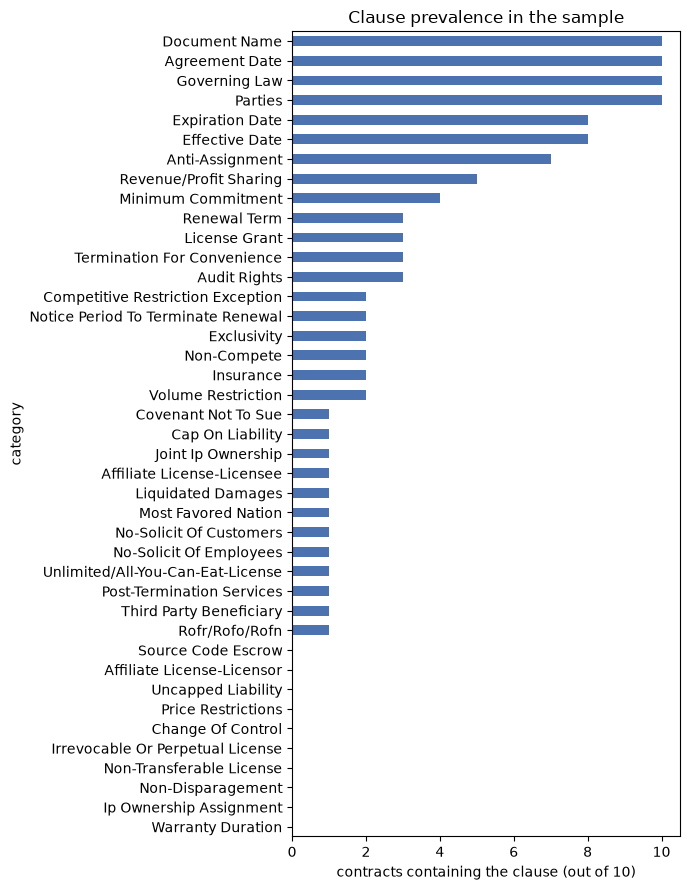

In [3]:
counts = labels.groupby("category")["present"].sum().sort_values()
ax = counts.plot.barh(figsize=(7, 9), color="#4C72B0")
ax.set_xlabel("contracts containing the clause (out of 10)")
ax.set_title("Clause prevalence in the sample")
plt.tight_layout(); (ROOT / "docs/images").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "docs/images/sample_clause_prevalence.png", dpi=120); plt.show()

## 3. Clause detection: TF-IDF baseline
We train one Logistic Regression per category on the cleaned text of the 408 CUAD training contracts (`Week 2/data/`), using the 7 benchmark categories the team chose for comparing classical and transformer models. Class weighting compensates for rare positives.

In [4]:
BASELINE = ["Anti-Assignment", "Change Of Control", "Insurance", "Renewal Term",
            "Notice Period To Terminate Renewal", "Audit Rights", "Termination For Convenience"]

train_text = pd.read_csv(ROOT / "Week 2/data/train_contracts_cleaned.csv")
train_text = train_text.groupby("contract_title")["clean_context"].apply(" ".join)
train_lab = pd.read_csv(ROOT / "Week 2/data/train_category_labels.csv", usecols=["contract_title", "category", "present"])
train_y = train_lab.pivot_table(index="contract_title", columns="category", values="present", aggfunc="max").loc[train_text.index]

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True, stop_words="english")
X_train = vec.fit_transform(train_text.values)
models = {c: LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train, train_y[c]) for c in BASELINE}
print("Trained", len(models), "classifiers on", X_train.shape[0], "contracts")

Trained 7 classifiers on 408 contracts


Now predict on the 10 sample contracts (which the model never saw) and compare with the expert annotations.

In [5]:
X_sample = vec.transform([c["paragraphs"][0]["context"] for c in sample["data"]])
titles = [c["title"] for c in sample["data"]]
truth = labels.pivot_table(index="contract_title", columns="category", values="present").loc[titles]

rows = []
for c, m in models.items():
    pred = m.predict(X_sample)
    rows.append({"category": c, "true_positives_in_sample": int(truth[c].sum()),
                 "predicted_positive": int(pred.sum()),
                 "f1": round(f1_score(truth[c], pred, zero_division=0), 2)})
pd.DataFrame(rows)

,category,true_positives_in_sample,predicted_positive,f1
0,Anti-Assignment,7,8,0.80
1,Change Of Control,0,0,0.00
2,Insurance,2,1,0.67
3,Renewal Term,3,2,0.40
4,Notice Period To Terminate Renewal,2,1,0.00
5,Audit Rights,3,2,0.80
6,Termination For Convenience,3,1,0.50


> With only 10 contracts these numbers are noisy. On the full 102-contract test set the TF-IDF baseline reaches **0.59 macro F1** on these 7 categories, and the fine-tuned DistilRoBERTa model reaches **0.71** (see `training/results/distilroberta_baseline/RESULTS.md`).

## 4. Contract risk triage
The risk layer turns detected clauses into a score with four auditable signals (clause risk levels, a severity floor for confident High-risk clauses, missing protections, and risky combinations). Cutoffs for the Low / Medium / High buckets come from the score distribution of the training contracts.

Here we use the **gold annotations** as the detected clauses, which shows the ceiling a perfect classifier would reach.

In [6]:
spec = importlib.util.spec_from_file_location("score_contracts", ROOT / "risk/score_contracts.py")
sc = importlib.util.module_from_spec(spec); spec.loader.exec_module(sc)

rubric = pd.read_csv(ROOT / "evaluation/risk_categories.csv")
levels = {sc.norm(c): (lvl, c) for c, lvl in zip(rubric["category"], rubric["initial_risk"])}
rules = json.loads((ROOT / "risk/risk_rules.json").read_text())

train_gold = sc.load_gold(ROOT / "data/cuad/train_separate_questions.json")
sample_gold = sc.load_gold(ROOT / "data/sample/sample_contracts.json")
scores, register, cuts = sc.run(sample_gold, train_gold, levels, rules)
print(f"Bucket cutoffs from training contracts: Medium >= {cuts[0]:.2f}, High >= {cuts[1]:.2f}")
scores = scores.sort_values("score", ascending=False)
scores[["contract_title", "risk_bucket", "score", "high_risk_clauses", "medium_risk_clauses"]].assign(contract_title=scores.contract_title.str[:60])

Bucket cutoffs from training contracts: Medium >= 10.00, High >= 16.00


,contract_title,risk_bucket,score,high_risk_clauses,medium_risk_clauses
9,IntegrityMediaInc_20010329_10-K405_EX-10.17_23...,Medium,11.0,1,5
1,BOLIVARMININGCORP_05_23_2003-EX-2.1-VISP WEB S...,Medium,10.0,1,4
7,CYBERIANOUTPOSTINC_07_09_1998-EX-10.13-PROMOTI...,Medium,10.0,1,7
8,STWRESOURCESHOLDINGCORP_08_06_2014-EX-10.1-COO...,Medium,10.0,0,7
4,XinhuaSportsEntertainmentLtd_20070221_F-1_EX-9...,Medium,8.0,1,3
6,Quaker Chemical Corporation - NON COMPETITION ...,Medium,7.0,1,2
0,EcoScienceSolutionsInc_20180406_8-K_EX-10.1_11...,Low,4.0,0,2
3,KENTUCKYUTILITIESCO_03_25_2003-EX-10.65-TRANSP...,Low,4.0,0,2
5,EMERALDHEALTHTHERAPEUTICSINC_06_10_2020-EX-4.5...,Low,4.0,0,2
2,ScansourceInc_20190509_10-Q_EX-10.2_11661422_E...,Low,2.0,0,0


### Why did the top contract get its score?
Every point traces back to a named reason, so a reviewer can audit the ranking.

In [7]:
top = scores.iloc[0]
print(top["contract_title"], "->", top["risk_bucket"], f"(score {top['score']})\n")
for reason in top["reasons"].split("; "):
    print(" -", reason)

IntegrityMediaInc_20010329_10-K405_EX-10.17_2373875_EX-10.17_Co-Branding Agreement -> Medium (score 11.0)

 - Exclusivity (High, p=1.00) +3.00
 - No cap on liability +2.00
 - Anti-Assignment (Medium, p=1.00) +1.00
 - Revenue / Profit Sharing (Medium, p=1.00) +1.00
 - Minimum Commitment (Medium, p=1.00) +1.00
 - License Grant (Medium, p=1.00) +1.00
 - Audit Rights (Medium, p=1.00) +1.00
 - Exclusive and committed to minimum purchases (combination) +1.00


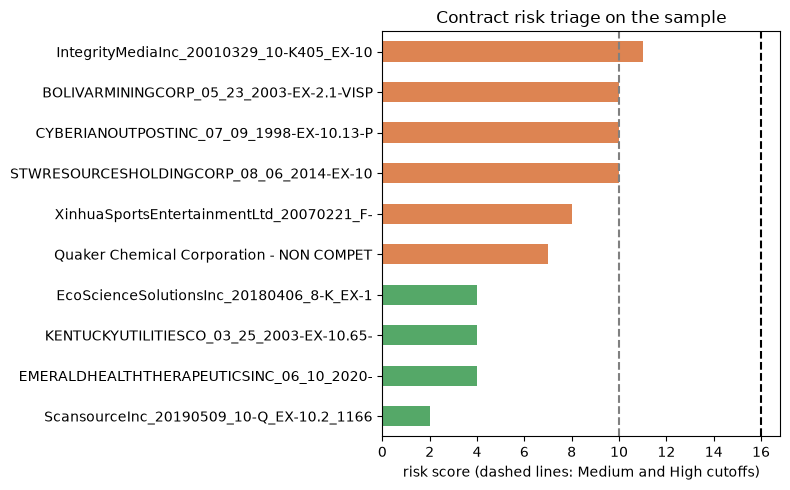

In [8]:
colors = {"High": "#C44E52", "Medium": "#DD8452", "Low": "#55A868"}
ax = scores.set_index(scores.contract_title.str[:40])["score"][::-1].plot.barh(
    figsize=(8, 5), color=[colors[b] for b in scores["risk_bucket"][::-1]])
ax.axvline(cuts[0], ls="--", c="gray"); ax.axvline(cuts[1], ls="--", c="black")
ax.set_xlabel("risk score (dashed lines: Medium and High cutoffs)"); ax.set_ylabel("")
ax.set_title("Contract risk triage on the sample")
plt.tight_layout(); plt.savefig(ROOT / "docs/images/sample_risk_triage.png", dpi=120); plt.show()

## Next steps
- Run the full pipeline on all 510 contracts: see the **Usage** section of the README.
- Swap gold labels for model predictions with `python risk/score_contracts.py --source model --run training/outputs/sqrt_weighted`.
- Adjust risk weights in `risk/risk_rules.json` without touching code, and re-run this notebook to see how the ranking changes.